In [2]:
%load_ext autoreload
%autoreload 2

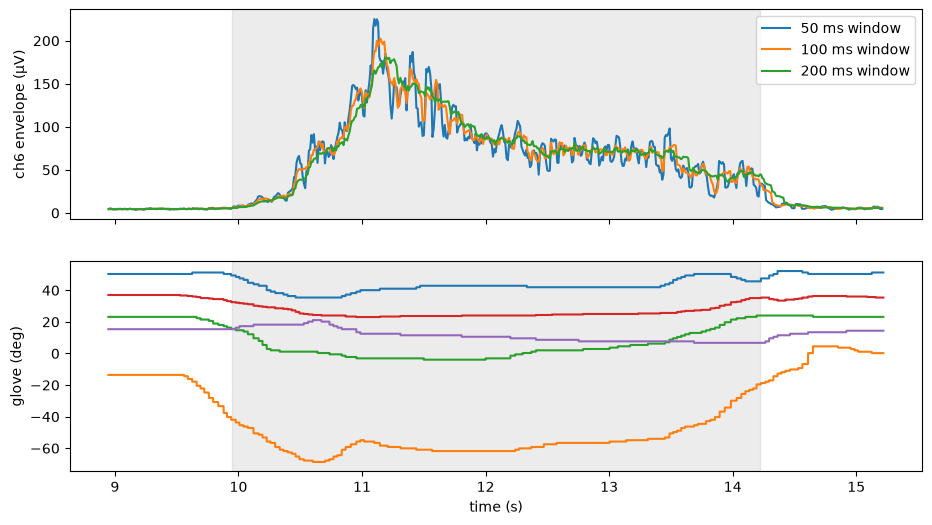

In [1]:
import numpy as np, scipy.io as sio, matplotlib.pyplot as plt
from scipy.signal import butter, sosfilt

d = sio.loadmat(r"D:\emg-project\data\raw\DB8\S1_E1_A1.mat")
emg    = d["emg"].astype(np.float64)
glove  = d["glove"].astype(np.float64)
restim = d["restimulus"].ravel()
rerep  = d["rerepetition"].ravel()

# Steps 1-2: the filters we just checked (causal)
aa = butter(4, 450, btype="lowpass",  fs=2000, output="sos")
hp = butter(2, 20,  btype="highpass", fs=1000, output="sos")
x = sosfilt(hp, sosfilt(aa, emg, axis=0)[::2], axis=0)      # clean EMG at 1000 Hz

# Step 3: causal moving RMS over the last W ms, one value every 10 ms
def moving_rms(x, win_ms, fs=1000, step_ms=10):
    N, step = int(win_ms * fs / 1000), int(step_ms * fs / 1000)
    cs = np.concatenate([np.zeros((1, x.shape[1])), np.cumsum(x**2, axis=0)])
    ends = np.arange(N, len(x) + 1, step)        # each window = the N samples before 'end'
    return np.sqrt((cs[ends] - cs[ends - N]) / N), ends

# Look at the first repetition of movement 1, with 1 s of rest on each side
seg = np.where((restim == 1) & (rerep == 1))[0]
t0, t1 = seg[0] / 2000 - 1.0, seg[-1] / 2000 + 1.0

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
for W in (50, 100, 200):
    env, ends = moving_rms(x, W)
    t = ends / 1000
    m = (t >= t0) & (t <= t1)
    ax[0].plot(t[m], env[m, 5] * 1e6, label=f"{W} ms window")
ax[0].set_ylabel("ch6 envelope (µV)"); ax[0].legend()

tg = np.arange(len(glove)) / 2000
mg = (tg >= t0) & (tg <= t1)
ax[1].plot(tg[mg], glove[mg, :5]); ax[1].set_ylabel("glove (deg)"); ax[1].set_xlabel("time (s)")
for a in ax: a.axvspan(seg[0] / 2000, seg[-1] / 2000, color="grey", alpha=0.15)
plt.show()

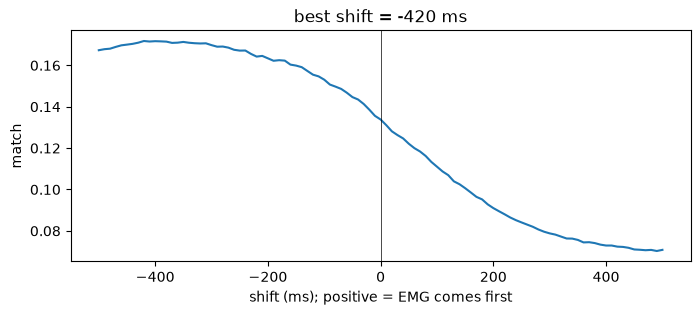

EMG lead after correcting for the 25 ms window delay: -395 ms


In [2]:
env, ends = moving_rms(x, 50)                      # 50 ms window -> 25 ms delay
g = glove[2 * (ends - 1)]                          # glove at the same moments (100 Hz)
speed = np.abs(np.diff(g, axis=0)).sum(axis=1)     # how fast the fingers are moving
act = env.sum(axis=1)[1:]                          # total muscle activity, all channels
a = (act - act.mean()) / act.std()
s = (speed - speed.mean()) / speed.std()

lags = np.arange(-50, 51)                          # -500 ms to +500 ms, in 10 ms steps
cc = [np.mean(a[max(0, -k):len(a) - max(0, k)] * s[max(0, k):len(s) - max(0, -k)]) for k in lags]
best = lags[np.argmax(cc)] * 10

plt.figure(figsize=(8, 3)); plt.plot(lags * 10, cc); plt.axvline(0, color="k", lw=0.5)
plt.xlabel("shift (ms); positive = EMG comes first"); plt.ylabel("match")
plt.title(f"best shift = {best} ms"); plt.show()
print("EMG lead after correcting for the 25 ms window delay:", best + 25, "ms")

80 repetitions measured
median EMG lead: 5.0 ms
middle 50% of values: [-107.5   57.5] ms
EMG came first in 51 % of repetitions


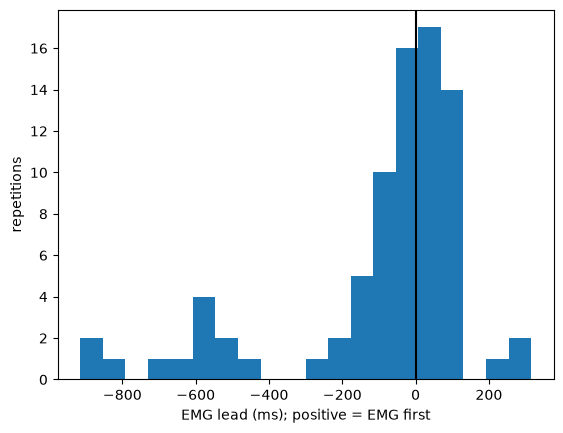

movement 1, repetition 10: -475 ms
movement 5, repetition 8: -535 ms
movement 6, repetition 1: -695 ms
movement 6, repetition 7: -605 ms
movement 7, repetition 2: -595 ms
movement 7, repetition 5: -485 ms
movement 8, repetition 1: -855 ms
movement 8, repetition 3: -585 ms
movement 8, repetition 4: -655 ms
movement 8, repetition 6: -915 ms
movement 8, repetition 7: -835 ms
movement 9, repetition 9: -585 ms


In [4]:
env, ends = moving_rms(x, 50)
k = 2 * (ends - 1)                       # raw-sample index matching each 10 ms step
g, rs, rr = glove[k], restim[k], rerep[k]
act = env.sum(axis=1)                    # total muscle activity, all channels

leads, info = [], []
for mov in range(1, 10):
    for rep in np.unique(rr[rs == mov]):
        start = np.where((rs == mov) & (rr == rep))[0][0]   # where the label says the movement starts
        if start < 120: continue
        pre = slice(start - 120, start - 60)                 # rest: 1.2 s to 0.6 s before the label
        win = slice(start - 60, start + 150)                 # search: 0.6 s before to 1.5 s after
        mu, sd = act[pre].mean(), act[pre].std()
        e_on = np.argmax(act[win] > mu + 5 * sd)             # EMG onset
        dist = np.linalg.norm(g[win] - g[pre].mean(axis=0), axis=1)
        g_on = np.argmax(dist > 5)                           # glove onset (moved > 5 degrees)
        if act[win][e_on] <= mu + 5 * sd or dist[g_on] <= 5:
            continue                                         # no clear onset, skip
        leads.append((g_on - e_on) * 10 + 25)                # ms; +25 corrects the window delay
        info.append((mov, rep))

leads = np.array(leads)
print(len(leads), "repetitions measured")
print("median EMG lead:", np.median(leads), "ms")
print("middle 50% of values:", np.percentile(leads, [25, 75]), "ms")
print("EMG came first in", round(np.mean(leads > 0) * 100), "% of repetitions")
plt.hist(leads, bins=20); plt.axvline(0, color="k")
plt.xlabel("EMG lead (ms); positive = EMG first"); plt.ylabel("repetitions"); plt.show()
for (mov, rep), L in zip(info, leads):
    if L < -300: print(f"movement {mov}, repetition {rep}: {L} ms")

d:\ML_Proj\envs\emg\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


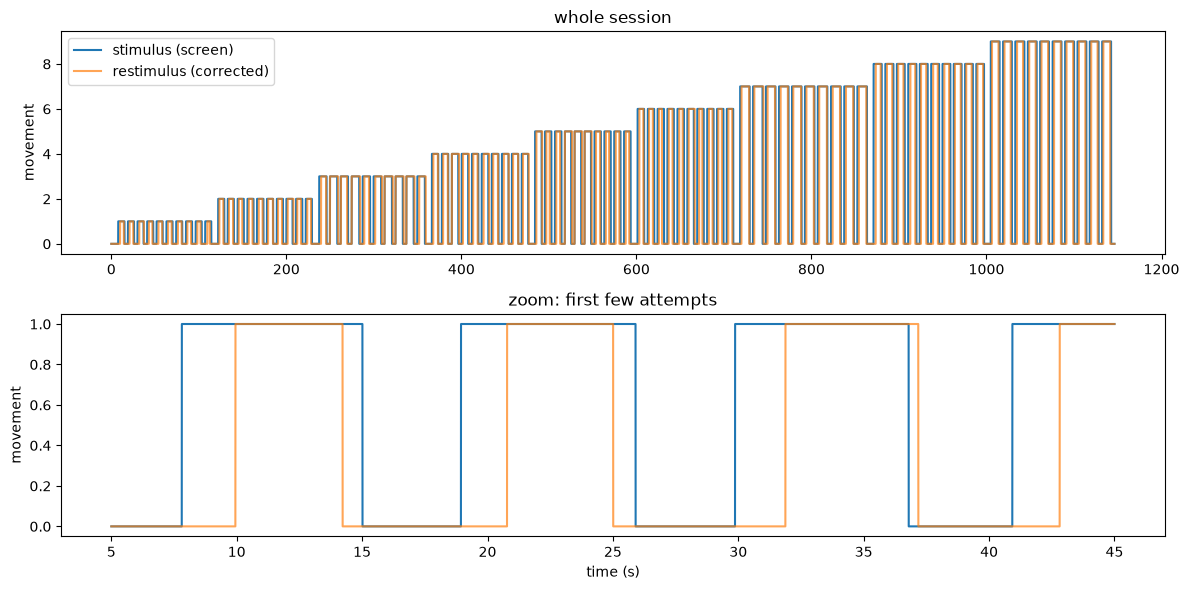

In [1]:
import numpy as np, scipy.io as sio, matplotlib.pyplot as plt
d = sio.loadmat(r"D:\emg-project\data\raw\DB8\S1_E1_A1.mat",
                variable_names=["stimulus", "restimulus"])
st, rs = d["stimulus"].ravel(), d["restimulus"].ravel()
t = np.arange(len(st)) / 2000

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(t, st, label="stimulus (screen)")
ax[0].plot(t, rs, label="restimulus (corrected)", alpha=0.7)
ax[0].set_ylabel("movement"); ax[0].set_title("whole session"); ax[0].legend()
m = (t > 5) & (t < 45)
ax[1].plot(t[m], st[m], label="stimulus"); ax[1].plot(t[m], rs[m], label="restimulus", alpha=0.7)
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("movement"); ax[1].set_title("zoom: first few attempts")
plt.tight_layout(); plt.show()